# Phân tích giá chào thuê nhà ở theo khu vực tại Hà Nội

## 1. Mục tiêu và câu hỏi nghiên cứu

Nghiên cứu mô tả giá chào thuê phòng trọ, căn hộ, nhà nguyên căn và biệt thự tại Hà Nội. Đơn vị quan sát là tin đăng, được xác định bằng cặp Nguồn – Mã tin. Số tin trong mẫu không đại diện cho số chỗ ở còn trống hoặc số giao dịch thuê thành công.

Các nội dung phân tích gồm phân bố giá theo loại chỗ ở, chênh lệch giá thuê và giá/m² giữa các khu vực, khả năng đáp ứng ngân sách và quan hệ giữa diện tích với giá. Phép so sánh cùng nhóm diện tích được sử dụng để xem xét mức chênh lệch khu vực trong điều kiện gần nhau hơn.

## 2. Nguồn và phạm vi dữ liệu

Mẫu được tổng hợp từ Phongtro123 và bộ Vietnam Real Estate Datasets – Catalyst. Dữ liệu Phongtro123 thu thập ngày 12/10/2026, xét các tin có nhãn thời gian danh sách thuộc năm 2025–2026. Catalyst là bản chụp ngày 29/12/2025. Nhãn cập nhật hoặc gia hạn chưa xác định ngày đăng đầu tiên, vì vậy nghiên cứu không xây dựng chuỗi biến động giá theo tháng.

| Thuộc tính | Nội dung và đơn vị |
|---|---|
| Nguồn, Mã tin | Nguồn dữ liệu và mã định danh trong từng nguồn |
| Loại chỗ ở, Mục đích thuê | Phòng trọ, căn hộ, nhà nguyên căn, biệt thự; thuê để ở hoặc kết hợp kinh doanh |
| Quận/huyện cũ | Tên khu vực lịch sử dùng làm hệ phân nhóm chung |
| Phường/xã mới | Đơn vị hiện hành đã xác định được từ thông tin địa chỉ |
| Giá thuê (đồng/tháng) | Giá chào thuê theo tháng |
| Diện tích (m²) | Diện tích sau kiểm tra tính hợp lệ |
| Giá thuê/m² (đồng/tháng) | Giá thuê tháng chia diện tích, đơn vị đồng/m²/tháng |

Bảng gộp đã thống nhất tên thuộc tính và đơn vị đo. Tin bán và tin chỉ phục vụ kinh doanh được loại khỏi phạm vi nhà ở cho thuê. Giá ngoài 0,5–500 triệu đồng/tháng, diện tích ngoài 5–1.000 m² và các giá chưa đủ căn cứ xác minh được giữ thiếu trong dữ liệu chuẩn hóa.

### Công cụ phân tích

Pandas hỗ trợ khảo sát và tổng hợp bảng dữ liệu; Matplotlib và Seaborn thể hiện kết quả bằng biểu đồ. NumPy cung cấp cận trên không giới hạn cho nhóm diện tích cuối.

PostgreSQL lưu dữ liệu và kết quả ETL; Psycopg cung cấp kết nối để đọc bảng phân tích.

In [1]:
import sys
sys.path.insert(0, "..")
from db.client import read_listings
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns

### Quy mô dữ liệu đầu vào

Dữ liệu của lần ETL thành công mới nhất được đọc từ PostgreSQL để xác định số quan sát và thuộc tính. Các biến giá thuê, giá/m², diện tích, khu vực và loại chỗ ở được sử dụng nhất quán trong các phép tổng hợp.

In [2]:
df = read_listings()
gia = "Giá thuê (đồng/tháng)"
giam2 = "Giá thuê/m² (đồng/tháng)"
dientich = "Diện tích (m²)"
khu_vuc = "Quận/huyện cũ"
loai = "Loại chỗ ở"
print("Số dòng, số cột:", df.shape)

Số dòng, số cột: (3027, 15)


### Các thuộc tính quan sát

Năm tin đầu thể hiện cấu trúc của các trường nguồn, mã tin, loại chỗ ở, khu vực, diện tích và giá thuê. Giá trị thiếu được giữ nguyên trong quá trình khảo sát.

In [3]:
df[["Nguồn", "Mã tin", loai, khu_vuc, dientich, gia]].head()

,Nguồn,Mã tin,Loại chỗ ở,Quận/huyện cũ,Diện tích (m²),Giá thuê (đồng/tháng)
0,Catalyst,100256,nhà nguyên căn,Gia Lâm,NaN,15000000.0
1,Catalyst,100851,nhà nguyên căn,Tây Hồ,NaN,14000000.0
2,Catalyst,100853,nhà nguyên căn,Đống Đa,NaN,16000000.0
3,Catalyst,100998,nhà nguyên căn,Thanh Xuân,NaN,24000000.0
4,Catalyst,100999,nhà nguyên căn,Đống Đa,NaN,17000000.0


Bảng gộp gồm **3.027 tin và 15 thuộc tính**, với 1.859 tin Phongtro123 và 1.168 tin Catalyst. Tên quận/huyện trước sắp xếp là hệ khu vực lịch sử dùng cho so sánh giữa hai nguồn.

## 3. Chất lượng dữ liệu và tập phân tích

### Kiểu dữ liệu và mức độ đầy đủ

Kiểu dữ liệu và số giá trị không thiếu xác định khả năng sử dụng của từng thuộc tính. Giá thuê, diện tích và giá/m² được biểu diễn bằng kiểu số để phục vụ thống kê.

In [4]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 3027 entries, 0 to 3026
Data columns (total 15 columns):
 #   Column                         Non-Null Count  Dtype  
---  ------                         --------------  -----  
 0   Nguồn                          3027 non-null   str    
 1   Mã tin                         3027 non-null   str    
 2   Liên kết tin gốc               3027 non-null   str    
 3   Tiêu đề                        3027 non-null   str    
 4   Quận/huyện cũ                  3027 non-null   str    
 5   Phường/xã được nêu             1620 non-null   str    
 6   Phường/xã mới                  871 non-null    str    
 7   Trạng thái xác định phường/xã  3027 non-null   str    
 8   Loại chỗ ở                     3027 non-null   str    
 9   Mục đích thuê                  3027 non-null   str    
 10  Diện tích (m²)                 2861 non-null   float64
 11  Trạng thái giá                 3027 non-null   str    
 12  Trạng thái diện tích           3027 non-null   str    
 13 

### Mức thiếu theo thuộc tính

Số ô thiếu và tỷ lệ thiếu phản ánh độ đầy đủ của dữ liệu. Mức thiếu địa chỉ giới hạn phân tích theo phường/xã; thiếu giá hoặc diện tích ảnh hưởng trực tiếp đến số tin tham gia các phép đo tương ứng.

In [5]:
thieu = pd.DataFrame({
    "Kiểu dữ liệu": df.dtypes.astype(str),
    "Số ô thiếu": df.isna().sum(),
    "Tỷ lệ thiếu (%)": df.isna().mean() * 100
})
thieu.sort_values("Số ô thiếu", ascending=False).round(1)

,Kiểu dữ liệu,Số ô thiếu,Tỷ lệ thiếu (%)
Phường/xã mới,str,2156,71.2
Phường/xã được nêu,str,1407,46.5
Giá thuê/m² (đồng/tháng),float64,193,6.4
Diện tích (m²),float64,166,5.5
Giá thuê (đồng/tháng),float64,51,1.7
Liên kết tin gốc,str,0,0.0
Nguồn,str,0,0.0
Tiêu đề,str,0,0.0
Quận/huyện cũ,str,0,0.0
Mã tin,str,0,0.0


Trong bảng gộp có **166 tin thiếu diện tích**, **51 giá thuê thiếu**, **193 giá/m² thiếu** và **2.156 tin chưa xác định được phường/xã mới**. Liên kết tin gốc đầy đủ; trường này phục vụ đối chiếu nguồn và không tham gia các phép thống kê giá.

### Tính duy nhất và miền giá trị

Cặp Nguồn – Mã tin xác định tính duy nhất của tin đăng trong bảng gộp. Miền giá và diện tích được đối chiếu với các giới hạn đã áp dụng trong quá trình chuẩn hóa.

In [6]:
print("Dòng trùng toàn bộ:", df.duplicated().sum())
print("Trùng khóa nguồn và mã tin:", df.duplicated(["Nguồn", "Mã tin"]).sum())
print("Giá ngoài miền hợp lệ:", (df[gia].notna() & ~df[gia].between(500_000, 500_000_000)).sum())
print("Diện tích ngoài miền hợp lệ:", (df[dientich].notna() & ~df[dientich].between(5, 1000)).sum())

Dòng trùng toàn bộ: 0
Trùng khóa nguồn và mã tin: 0
Giá ngoài miền hợp lệ: 0
Diện tích ngoài miền hợp lệ: 0


### Thống kê mô tả các đại lượng số

Thống kê giá thuê, diện tích và giá/m² mô tả mức trung tâm, độ phân tán và khoảng giá trị. Mỗi thuộc tính được tính trên các quan sát không thiếu của chính thuộc tính đó.

In [7]:
df[[gia, dientich, giam2]].describe().round(2)

,Giá thuê (đồng/tháng),Diện tích (m²),Giá thuê/m² (đồng/tháng)
count,2.976000e+03,2861.00,2834.00
mean,1.128267e+07,44.77,194938.15
std,1.865773e+07,46.85,127804.26
min,7.000000e+05,5.00,6000.00
25%,3.000000e+06,22.00,122857.00
50%,4.200000e+06,29.00,156000.00
75%,1.000000e+07,45.00,222222.00
max,3.000000e+08,851.00,1625000.00


### Thuộc tính trong tập phân tích

Tập phân tích được tách từ bảng chuẩn hóa, bỏ liên kết tin và hai trường phường/xã. Khu vực quận/huyện lịch sử được giữ làm đơn vị phân nhóm; dữ liệu nguồn được bảo toàn.

In [8]:
data = df.drop(columns=["Liên kết tin gốc", "Phường/xã mới", "Phường/xã được nêu"]).copy()

### Xử lý bản ghi trùng

Các dòng trùng toàn bộ và trùng cặp Nguồn – Mã tin được loại khỏi tập phân tích. Kết quả khảo sát hiện tại không có bản ghi trùng, nên quy mô mẫu không giảm ở bước này.

In [9]:
so_dong_truoc = len(data)
data = data.drop_duplicates()
data = data.drop_duplicates(subset=["Nguồn", "Mã tin"])
print("Số dòng trùng đã loại:", so_dong_truoc - len(data))

Số dòng trùng đã loại: 0


### Xử lý thiếu diện tích

Tập phân tích loại các tin thiếu diện tích để thống nhất nền dữ liệu cho phép so sánh giá, diện tích và giá/m². Giá thuê và giá/m² thiếu được giữ nguyên.

In [10]:
so_dong_truoc = len(data)
data = data.dropna(subset=[dientich])
print("Số dòng thiếu diện tích đã loại:", so_dong_truoc - len(data))
print("Số dòng, số cột còn lại:", data.shape)
print("Số khu vực:", data[khu_vuc].nunique())
print("Giá thuê thiếu:", data[gia].isna().sum())
print("Giá/m² thiếu:", data[giam2].isna().sum())

Số dòng thiếu diện tích đã loại: 166
Số dòng, số cột còn lại: (2861, 12)
Số khu vực: 23
Giá thuê thiếu: 27
Giá/m² thiếu: 27


Sau xử lý, tập phân tích gồm **2.861 tin, 12 thuộc tính và 23 khu vực**. Có 166 tin thiếu diện tích bị loại, còn **27 giá thuê thiếu và 27 giá/m² thiếu**. Tập này không có dòng trùng, khóa tin trùng hoặc diện tích thiếu.

### Đơn vị biểu diễn giá

Giá thuê được biểu diễn theo triệu đồng/tháng và giá/m² theo nghìn đồng/m²/tháng. Hai chỉ số được tính từ các trường chuẩn hóa, bảo toàn giá trị gốc để đối chiếu.

In [11]:
gia_trieu = "Giá (triệu đồng/tháng)"
gia_nghin = "Giá/m² (nghìn đồng/tháng)"
data[gia_trieu] = data[gia] / 1_000_000
data[gia_nghin] = data[giam2] / 1_000
data[[gia_trieu, dientich, gia_nghin]].describe().round(2)

,Giá (triệu đồng/tháng),Diện tích (m²),Giá/m² (nghìn đồng/tháng)
count,2834.00,2861.00,2834.00
mean,10.41,44.77,194.94
std,15.89,46.85,127.80
min,0.70,5.00,6.00
25%,3.00,22.00,122.86
50%,4.00,29.00,156.00
75%,8.00,45.00,222.22
max,229.00,851.00,1625.00


### Kết quả kiểm tra sau xử lý

Mức thiếu diện tích và tính duy nhất được kiểm tra lại trên tập phân tích. Những tin có giá dương hình thành mẫu dùng để tính mức giá; cơ cấu nguồn được xác định bằng số tin còn lại.

In [12]:
print("Dòng trùng:", data.duplicated().sum())
print("Khóa tin trùng:", data.duplicated(["Nguồn", "Mã tin"]).sum())
print("Diện tích thiếu:", data[dientich].isna().sum())
co_gia = data.loc[data[gia].gt(0)].copy()
print("Tin đủ giá và diện tích:", len(co_gia))
data["Nguồn"].value_counts().to_frame("Số tin sau xử lý")

Dòng trùng: 0
Khóa tin trùng: 0
Diện tích thiếu: 0
Tin đủ giá và diện tích: 2834


,Số tin sau xử lý
Nguồn,
Phongtro123,1855
Catalyst,1006


## 4. Phân tích giá theo khu vực

Các phép phân tích sử dụng cùng tập dữ liệu sau xử lý. So sánh khu vực tập trung vào cùng loại phòng trọ nhằm hạn chế ảnh hưởng của cơ cấu chỗ ở. Số tin của mỗi nhóm được xác định trong bảng tổng hợp; tên quận/huyện là nhãn khu vực lịch sử.

### Biểu đồ 1. Phân bố giá theo loại chỗ ở

Phân bố giá xác định các mức chào thuê phổ biến và mức độ lệch của từng loại chỗ ở. Trung vị được tính trên toàn bộ tin có giá; histogram hiển thị đến phân vị 99% của từng nhóm.

In [13]:
thu_tu = ["phòng trọ", "căn hộ", "nhà nguyên căn", "biệt thự"]
thong_ke_loai = co_gia.groupby(loai)[gia_trieu].agg(["count", "median"])
thong_ke_loai.round(2)

,count,median
Loại chỗ ở,,
biệt thự,24,50.0
căn hộ,281,4.6
nhà nguyên căn,727,29.0
phòng trọ,1802,3.5


Bốn khung phân bố thể hiện riêng từng loại chỗ ở. Đường đỏ xác định vị trí trung vị trong mỗi phân phối.

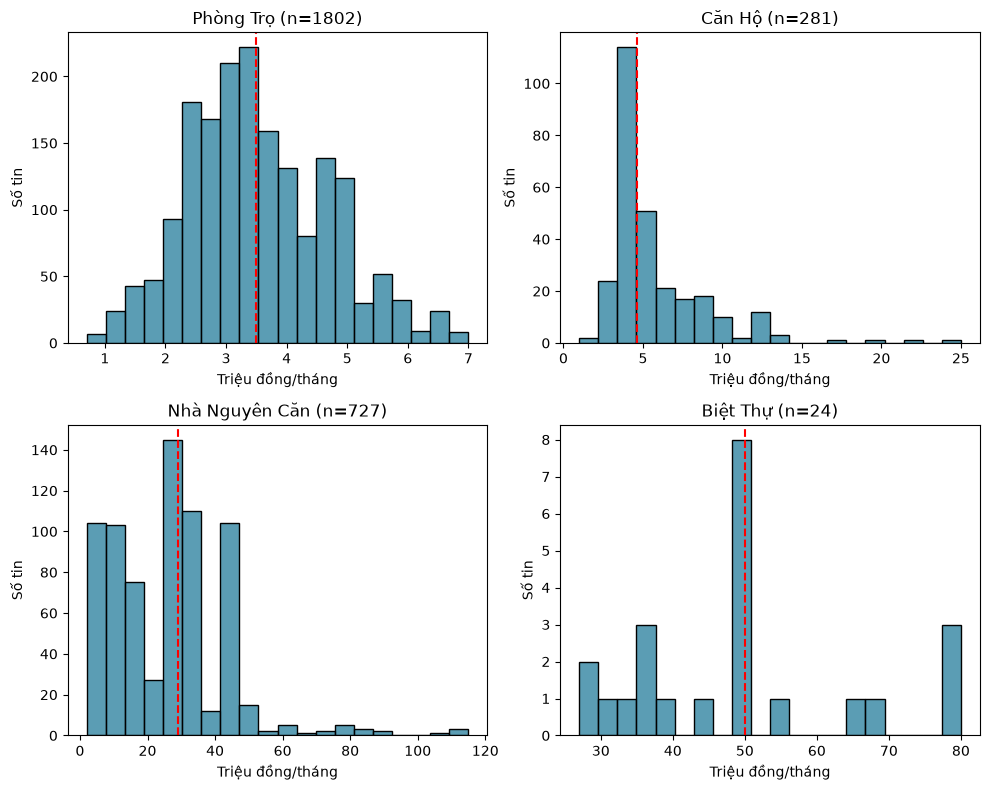

In [14]:
plt.figure(figsize=(10, 8))
for i, kind in enumerate(thu_tu, 1):
    plt.subplot(2, 2, i)
    x = co_gia.loc[co_gia[loai] == kind, gia_trieu]
    sns.histplot(x[x <= x.quantile(.99)], bins=20, color="#247C9B")
    plt.axvline(x.median(), color="red", linestyle="--")
    plt.title(f"{kind.title()} (n={len(x)})")
    plt.xlabel("Triệu đồng/tháng")
    plt.ylabel("Số tin")
plt.tight_layout()
plt.show()

**Nhận xét**

Phòng trọ có giá trung vị 3,5 triệu đồng/tháng trên 1.802 tin; căn hộ là 4,6 triệu với 281 tin. Nhà nguyên căn đạt 29 triệu trên 727 tin, còn biệt thự đạt 50 triệu với 24 tin. Các phân phối có đuôi kéo về phía giá cao, nên một vài tin đắt không mô tả tốt mức giá thường gặp. Trung vị nhà nguyên căn cao hơn phòng trọ khoảng 8,3 lần, trong khi chênh giữa căn hộ và phòng trọ khoảng 1,1 triệu đồng/tháng.

Loại chỗ ở là điều kiện cần giữ cố định trước khi so sánh khu vực hoặc chọn ngân sách. Một mức giá chung cho toàn bộ mẫu có thể bị ảnh hưởng bởi tỷ lệ nhà nguyên căn và căn hộ của mỗi nguồn. Trong phạm vi các tin thu thập, phòng trọ tập trung ở dải giá phù hợp hơn với ngân sách cá nhân; nhà nguyên căn và biệt thự cần được xem như lựa chọn có quy mô sử dụng khác. Nhóm biệt thự ít quan sát nên chưa đủ để suy rộng mặt bằng giá của toàn thị trường.

### Biểu đồ 2. Giá phòng trọ trung vị theo khu vực

Giá phòng trọ được tổng hợp theo khu vực bằng số tin và trung vị. Phạm vi so sánh gồm những khu vực có ít nhất 20 tin có giá.

In [15]:
phong_gia = co_gia.loc[co_gia[loai].eq("phòng trọ")].copy()
gia_kv = phong_gia.groupby(khu_vuc)[gia_trieu].agg(["size", "median"])
gia_kv = gia_kv.loc[gia_kv["size"].ge(20)].sort_values("median")
gia_kv.round(2)

,size,median
Quận/huyện cũ,,
Hoài Đức,56,2.90
Hai Bà Trưng,112,3.00
Hoàng Mai,140,3.00
Long Biên,34,3.00
Bắc Từ Liêm,206,3.20
Ba Đình,81,3.50
Tây Hồ,75,3.50
Thanh Trì,81,3.50
Đống Đa,150,3.58


Biểu đồ thanh ngang biểu diễn mức giá phòng trọ trung vị của các khu vực đủ mẫu.

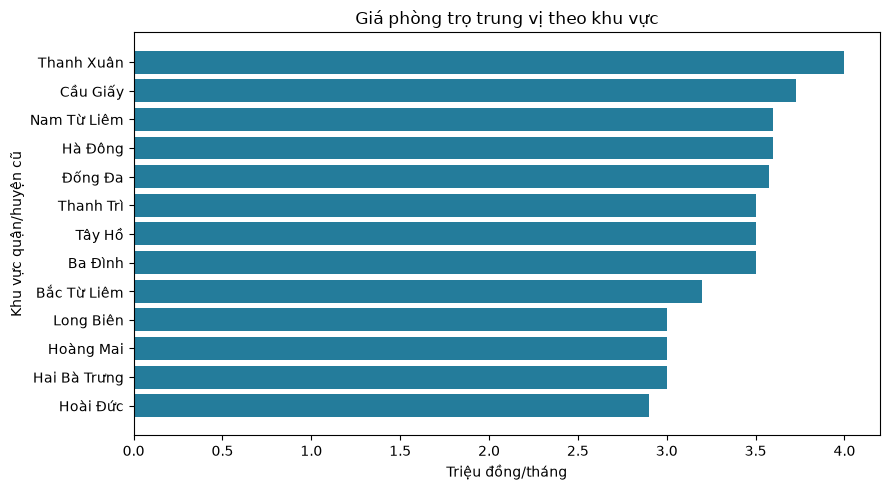

In [16]:
plt.figure(figsize=(9, 5))
plt.barh(gia_kv.index, gia_kv["median"], color="#247C9B")
plt.title("Giá phòng trọ trung vị theo khu vực")
plt.xlabel("Triệu đồng/tháng")
plt.ylabel("Khu vực quận/huyện cũ")
plt.tight_layout()
plt.show()

**Nhận xét**

Trong 13 khu vực đủ mẫu, Hoài Đức có giá phòng trọ trung vị 2,9 triệu đồng/tháng với 56 tin; Thanh Xuân có mức 4,0 triệu với 161 tin. Chênh lệch là 1,1 triệu đồng/tháng, tương đương khoảng 37,9% so với Hoài Đức. Hai Bà Trưng, Hoàng Mai và Long Biên cùng có trung vị 3,0 triệu; Cầu Giấy đạt 3,725 triệu trên 228 tin. Tổng số tin tham gia so sánh là 1.770, vì các khu vực ít hơn 20 tin không được xếp hạng.

Người thuê trong mẫu có thể dùng Hoài Đức, Hoàng Mai hoặc Hai Bà Trưng làm điểm bắt đầu tìm mức giá gần 3 triệu. Tuy nhiên, trung vị không bảo đảm mọi tin trong một khu vực có giá thấp hơn khu vực khác. Vị trí cụ thể, diện tích và điều kiện phòng chưa được kiểm soát hoàn toàn trong phép so sánh này. Kết quả xác định chênh lệch giữa các nhóm tin quan sát được, chưa chứng minh khu vực là nguyên nhân duy nhất của khác biệt giá.

### Biểu đồ 3. Mức giá theo khu vực và loại chỗ ở

Tổng hợp đồng thời khu vực và loại chỗ ở giúp phân biệt chênh lệch mức giá với khác biệt cơ cấu sản phẩm. Các nhóm dưới 10 tin được để trống, không thay bằng mức giá 0.

In [17]:
nhom = co_gia.groupby([khu_vuc, loai])[gia_trieu]
trung_vi = nhom.median().unstack().reindex(columns=thu_tu)
so_tin = nhom.size().unstack().reindex_like(trung_vi).fillna(0)
trung_vi = trung_vi.where(so_tin >= 10).dropna(how="all")
trung_vi.round(1)

Loại chỗ ở,phòng trọ,căn hộ,nhà nguyên căn,biệt thự
Quận/huyện cũ,,,,
Ba Đình,3.5,8.5,31.0,NaN
Bắc Từ Liêm,3.2,4.0,NaN,NaN
Cầu Giấy,3.7,5.5,31.0,NaN
Hai Bà Trưng,3.0,4.6,30.0,NaN
Hoài Đức,2.9,NaN,NaN,NaN
Hoàn Kiếm,3.9,NaN,28.5,NaN
Hoàng Mai,3.0,4.2,10.8,NaN
Hà Đông,3.6,3.8,8.5,NaN
Long Biên,3.0,NaN,11.0,NaN


Ma trận màu thể hiện mức giá trung vị theo từng cặp khu vực và loại chỗ ở.

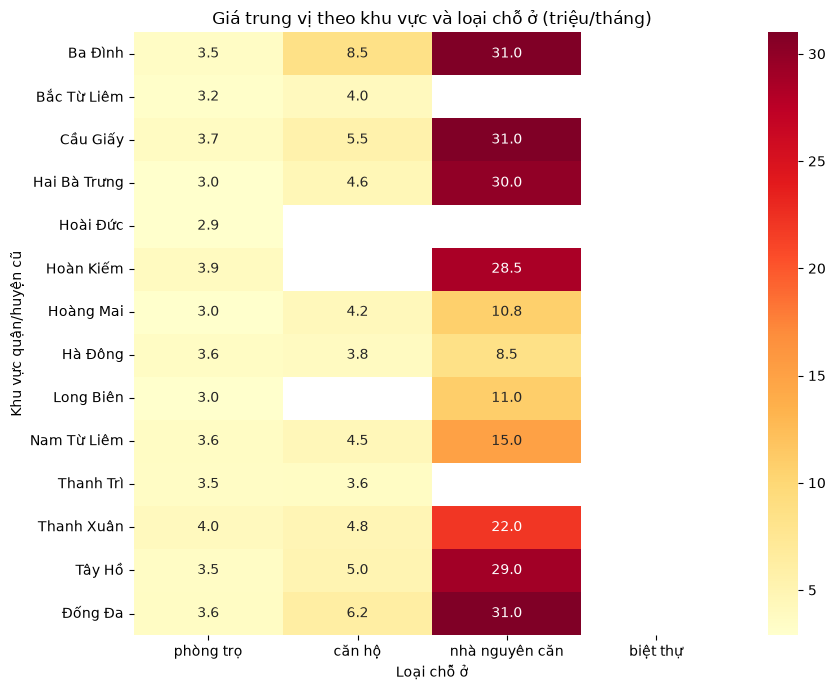

In [18]:
plt.figure(figsize=(9, 7))
sns.heatmap(trung_vi, annot=True, fmt=".1f", cmap="YlOrRd")
plt.title("Giá trung vị theo khu vực và loại chỗ ở (triệu/tháng)")
plt.xlabel("Loại chỗ ở")
plt.ylabel("Khu vực quận/huyện cũ")
plt.xticks(rotation=0)
plt.tight_layout()
plt.show()

**Nhận xét**

Giá căn hộ trung vị tại Thanh Trì là 3,6 triệu đồng/tháng với 29 tin, còn Ba Đình đạt 8,5 triệu với 21 tin. Nhà nguyên căn tại Hà Đông có trung vị 8,5 triệu trên 35 tin; Đống Đa đạt 31 triệu trên 130 tin. Mức giá căn hộ và nhà nguyên căn vì vậy khác nhau đáng kể ngay khi cùng xét từng khu vực. Các ô trống là nhóm không đủ 10 tin, không được hiểu thành không có chỗ ở hoặc có giá bằng 0; biệt thự chưa có khu vực đạt ngưỡng mẫu.

Heatmap giúp tránh chọn khu vực dựa trên một mức trung vị gộp nhiều loại nhà. Hà Đông có thể đáng khảo sát với nhà nguyên căn trong mẫu này, trong khi giá căn hộ thấp được quan sát tại Thanh Trì. Cơ cấu diện tích, số tầng và phân khúc dự án vẫn có thể khác nhau giữa các nhóm. Vì chưa kiểm soát những thuộc tính đó, kết luận phù hợp là định hướng danh sách tìm kiếm theo loại chỗ ở, thay vì khẳng định chênh lệch phản ánh cùng một sản phẩm thuê.

### Biểu đồ 4. Độ phân tán giá phòng trọ theo khu vực

Hai phân vị 25% và 75% xác định khoảng giữa của phân phối giá phòng trọ. Các khu vực đủ mẫu được so sánh bằng boxplot; điểm ngoại lệ không hiển thị riêng nhưng vẫn thuộc dữ liệu thống kê.

In [19]:
thu_tu_kv = gia_kv.index.tolist()
phong_kv = phong_gia.loc[phong_gia[khu_vuc].isin(thu_tu_kv)]
phan_vi = phong_kv.groupby(khu_vuc)[gia_trieu].quantile([.25, .75]).unstack()
phan_vi.columns = ["Phân vị 25%", "Phân vị 75%"]
phan_vi.round(2)

,Phân vị 25%,Phân vị 75%
Quận/huyện cũ,,
Ba Đình,2.50,4.50
Bắc Từ Liêm,2.50,3.80
Cầu Giấy,2.80,4.62
Hai Bà Trưng,2.50,4.43
Hoài Đức,2.40,3.22
Hoàng Mai,2.48,4.00
Hà Đông,3.20,4.00
Long Biên,2.72,4.00
Nam Từ Liêm,2.90,4.50


Boxplot thể hiện trung vị, khoảng giữa và mức phân tán giá phòng trọ của từng khu vực.

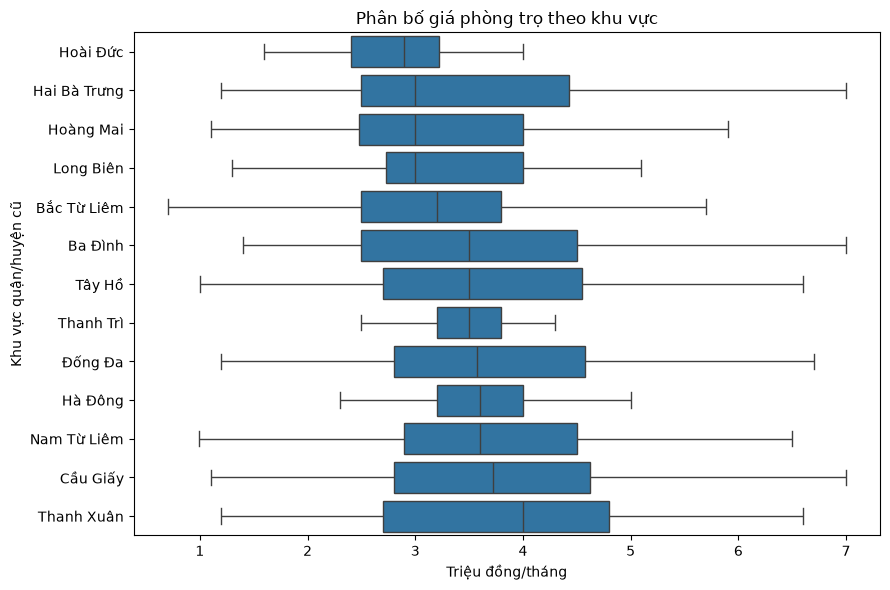

In [20]:
plt.figure(figsize=(9, 6))
sns.boxplot(data=phong_kv, x=gia_trieu, y=khu_vuc,
            order=thu_tu_kv, showfliers=False)
plt.title("Phân bố giá phòng trọ theo khu vực")
plt.xlabel("Triệu đồng/tháng")
plt.ylabel("Khu vực quận/huyện cũ")
plt.tight_layout()
plt.show()

**Nhận xét**

Khoảng giữa 50% tin phòng trọ tại Thanh Trì nằm từ 3,2 đến 3,8 triệu đồng/tháng, độ rộng 0,6 triệu. Tại Thanh Xuân, hai phân vị tương ứng là 2,7 và 4,8 triệu, độ rộng 2,1 triệu. Hoài Đức có khoảng giữa từ 2,4 đến 3,225 triệu; Nam Từ Liêm từ 2,9 đến 4,5 triệu. Như vậy, một khu vực có trung vị cao vẫn có thể chứa nhiều tin nằm trong dải giá thấp hơn, và các khoảng giá của nhiều khu vực chồng lấn.

Việc chọn nơi thuê nên xét cả vùng giá tập trung và độ phân tán, thay vì chỉ theo thứ hạng trung vị. Thanh Trì có dải giá giữa hẹp hơn, còn Thanh Xuân mang nhiều mức lựa chọn khác nhau trong mẫu. Các điểm vượt hàng rào boxplot không hiển thị riêng để giữ hình dễ đọc, nhưng vẫn thuộc dữ liệu khi tính thống kê. Phân tán giá có thể liên quan đến diện tích, vị trí chi tiết và tiện nghi; dữ liệu hiện có chưa đủ để tách đóng góp của từng yếu tố.

### Biểu đồ 5. Giá phòng trọ trên mỗi m² theo khu vực

Giá/m² bổ sung góc nhìn về chi phí cho một đơn vị diện tích. Phép so sánh sử dụng các tin đủ giá và diện tích, với tối thiểu 20 tin trong mỗi khu vực.

In [21]:
phong_m2 = phong_gia.loc[phong_gia[gia_nghin].gt(0)]
gia_m2_kv = phong_m2.groupby(khu_vuc)[gia_nghin].agg(["size", "median"])
gia_m2_kv = gia_m2_kv.loc[gia_m2_kv["size"].ge(20)].sort_values("median")
gia_m2_kv.round(2)

,size,median
Quận/huyện cũ,,
Long Biên,34,107.80
Hoài Đức,56,111.49
Bắc Từ Liêm,206,126.19
Hoàng Mai,140,135.50
Tây Hồ,75,140.00
Hai Bà Trưng,112,140.62
Thanh Trì,81,144.00
Nam Từ Liêm,289,145.00
Ba Đình,81,145.83


Biểu đồ thanh ngang so sánh giá phòng trọ trung vị trên mỗi m² giữa các khu vực.

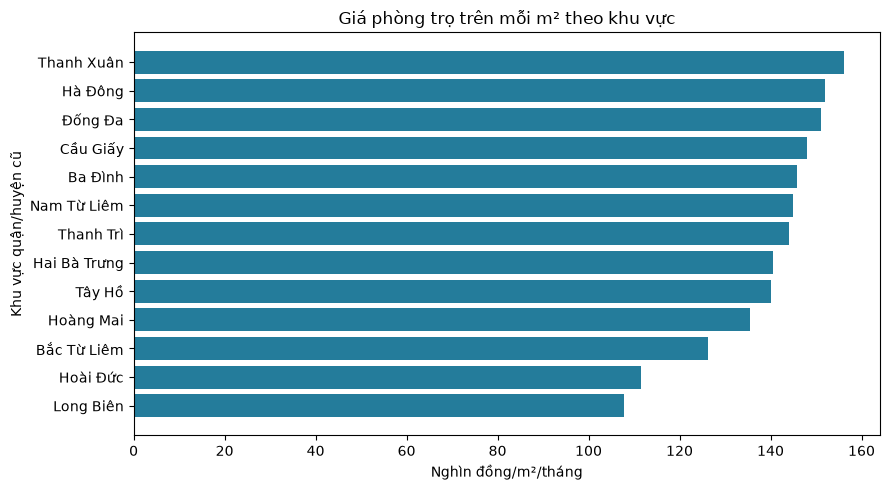

In [22]:
plt.figure(figsize=(9, 5))
plt.barh(gia_m2_kv.index, gia_m2_kv["median"], color="#247C9B")
plt.title("Giá phòng trọ trên mỗi m² theo khu vực")
plt.xlabel("Nghìn đồng/m²/tháng")
plt.ylabel("Khu vực quận/huyện cũ")
plt.tight_layout()
plt.show()

**Nhận xét**

Long Biên có giá phòng trọ trên mỗi m² trung vị khoảng 107,8 nghìn đồng/tháng trên 34 tin; Thanh Xuân đạt 156,25 nghìn với 161 tin. Mức Thanh Xuân cao hơn khoảng 44,9% so với Long Biên. Hoài Đức ở khoảng 111,5 nghìn, Bắc Từ Liêm khoảng 126,2 nghìn; Đống Đa, Hà Đông và Cầu Giấy đều từ 148 nghìn trở lên. Thứ hạng theo giá/m² khác một phần thứ hạng tổng giá thuê, vì diện tích của các phòng không đồng nhất.

Giá/m² bổ sung góc nhìn về số tiền trả cho một đơn vị diện tích, hữu ích khi so các phòng cùng loại. Một phòng có tổng giá thấp vẫn có thể đắt trên mỗi m² nếu diện tích nhỏ, nên hai chỉ số cần được đọc cùng nhau. Long Biên và Hoài Đức là những khu vực có tỷ lệ giá trên diện tích thấp hơn trong mẫu đủ dữ liệu. Chỉ số này không phản ánh đầy đủ chất lượng sử dụng, khu vực chung hoặc cách đo diện tích của người đăng tin, vì vậy không được dùng riêng để kết luận phòng nào tốt hơn.

## 5. Lựa chọn khu vực theo ngân sách

### Biểu đồ 6. Tỷ lệ phòng trọ đáp ứng ngân sách theo khu vực

Tỷ lệ đáp ứng xác định phần tin có giá không vượt 3, 5 hoặc 7 triệu đồng/tháng trong từng khu vực đủ mẫu. Ba ngưỡng ngân sách được tính tích lũy trên cùng tập tin có giá.

In [23]:
ty_le = pd.DataFrame(index=thu_tu_kv)
for ngan_sach in [3, 5, 7]:
    dap_ung = phong_kv[gia_trieu].le(ngan_sach)
    ty_le[f"Không quá {ngan_sach} triệu"] = dap_ung.groupby(phong_kv[khu_vuc]).mean() * 100
ty_le = ty_le.sort_values("Không quá 3 triệu", ascending=False)
ty_le.round(1)

,Không quá 3 triệu,Không quá 5 triệu,Không quá 7 triệu
Hoài Đức,67.9,100.0,100.0
Long Biên,52.9,94.1,100.0
Hai Bà Trưng,51.8,89.3,97.3
Hoàng Mai,51.4,97.9,100.0
Bắc Từ Liêm,49.0,95.6,100.0
Ba Đình,42.0,82.7,98.8
Tây Hồ,37.3,90.7,98.7
Thanh Xuân,36.0,83.9,100.0
Đống Đa,35.3,82.0,97.3
Nam Từ Liêm,34.9,89.6,100.0


Ma trận tỷ lệ thể hiện khả năng gặp tin trong từng mức ngân sách tại các khu vực được so sánh.

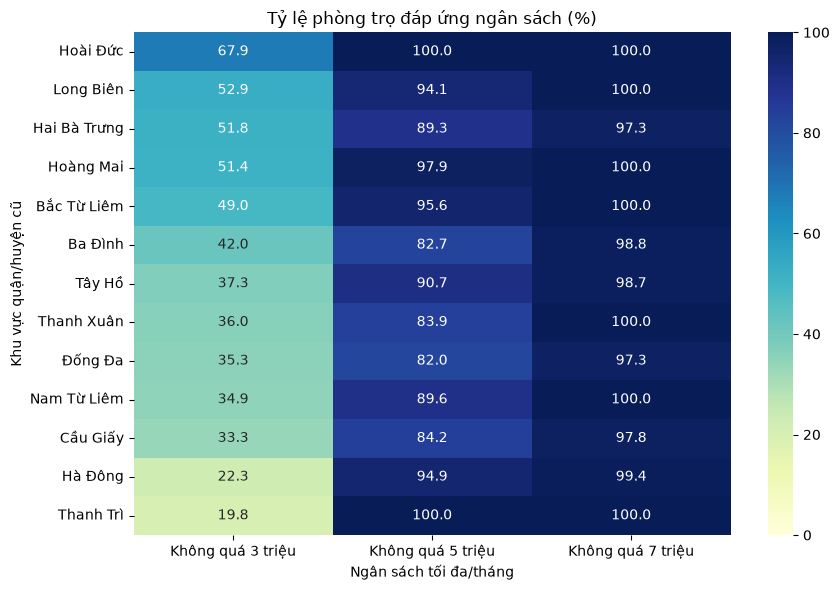

In [24]:
plt.figure(figsize=(9, 6))
sns.heatmap(ty_le, annot=True, fmt=".1f", cmap="YlGnBu", vmin=0, vmax=100)
plt.title("Tỷ lệ phòng trọ đáp ứng ngân sách (%)")
plt.xlabel("Ngân sách tối đa/tháng")
plt.ylabel("Khu vực quận/huyện cũ")
plt.tight_layout()
plt.show()

**Nhận xét**

Với ngân sách tối đa 3 triệu đồng/tháng, tỷ lệ phòng trọ đáp ứng tại Hoài Đức là 67,9%, Long Biên 52,9%, Hai Bà Trưng 51,8% và Hoàng Mai 51,4%. Tại Hà Đông, tỷ lệ tương ứng khoảng 22,3%. Chênh lệch giữa Hoài Đức và Hà Đông xấp xỉ 45,6 điểm phần trăm. Khi tăng ngân sách lên 5 hoặc 7 triệu, tỷ lệ đáp ứng tăng ở mọi khu vực vì các ngưỡng được tính tích lũy trên cùng tập tin có giá.

Đối với người ưu tiên hạn chế tiền thuê, Hoài Đức là điểm tìm kiếm đáng cân nhắc trong mẫu này; các khu vực có trung vị tương tự vẫn có tỷ lệ tin dưới 3 triệu khác nhau. Tỷ lệ giúp so khả năng gặp một tin trong ngân sách, nhưng không diễn giải thành xác suất thuê thành công hoặc tỷ lệ phòng còn trống. Mỗi khu vực có số tin và cơ cấu nguồn khác nhau, nên cần đọc cùng bảng số lượng lựa chọn và tin cụ thể trước khi đưa ra quyết định.

### Biểu đồ 7. Số tin phòng trọ trong từng khoảng ngân sách

Số tin được xác định riêng cho các khoảng 2–<3, 3–<5 và 5–7 triệu đồng/tháng. Các khoảng không chồng lấn; số đếm phản ánh lựa chọn quan sát được trong mẫu thu thập.

In [25]:
so_lua_chon = pd.DataFrame(index=thu_tu_kv)
for label, lower, upper in [("2–<3 triệu", 2, 3), ("3–<5 triệu", 3, 5), ("5–7 triệu", 5, 7)]:
    p = phong_kv[gia_trieu]
    mask = p.ge(lower) & (p.le(upper) if upper == 7 else p.lt(upper))
    so_lua_chon[label] = phong_kv.loc[mask].groupby(khu_vuc).size().reindex(thu_tu_kv, fill_value=0)
so_lua_chon = so_lua_chon.loc[so_lua_chon.sum(axis=1).sort_values(ascending=False).index]
so_lua_chon

,2–<3 triệu,3–<5 triệu,5–7 triệu
Nam Từ Liêm,69,169,45
Cầu Giấy,44,119,44
Bắc Từ Liêm,62,111,13
Thanh Xuân,39,79,34
Hà Đông,17,124,10
Đống Đa,32,75,28
Hoàng Mai,51,64,10
Hai Bà Trưng,37,52,12
Thanh Trì,11,61,7
Ba Đình,18,39,14


Ma trận số lượng thể hiện phân bố tin phòng trọ theo khu vực và khoảng giá thuê.

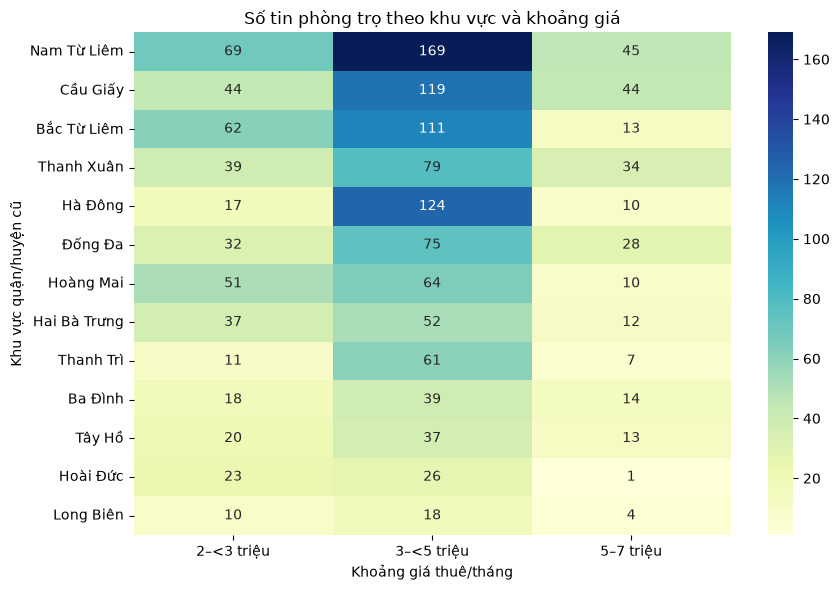

In [26]:
plt.figure(figsize=(9, 6))
sns.heatmap(so_lua_chon, annot=True, fmt="d", cmap="YlGnBu")
plt.title("Số tin phòng trọ theo khu vực và khoảng giá")
plt.xlabel("Khoảng giá thuê/tháng")
plt.ylabel("Khu vực quận/huyện cũ")
plt.tight_layout()
plt.show()

**Nhận xét**

Trong khoảng từ 3 đến dưới 5 triệu đồng/tháng, Nam Từ Liêm có 169 tin phòng trọ, Hà Đông 124 tin, Cầu Giấy 119 tin và Bắc Từ Liêm 111 tin. Nam Từ Liêm có nhiều lựa chọn quan sát được nhất trong dải này, dù không đứng đầu về tỷ lệ phòng dưới 3 triệu. Các khoảng 2–<3, 3–<5 và 5–7 triệu được đếm riêng, nên một tin không xuất hiện đồng thời ở hai khoảng liền nhau.

Số tin và tỷ lệ đáp ứng trả lời hai câu hỏi khác nhau: khu vực có nhiều lựa chọn trong mẫu không nhất thiết có tỷ trọng tin rẻ lớn nhất. Người thuê ngân sách 3–<5 triệu có thể ưu tiên khảo sát Nam Từ Liêm, Hà Đông hoặc Cầu Giấy để xem nhiều tin cụ thể hơn, rồi dùng diện tích và giá/m² để thu hẹp. Số lượng phản ánh độ phủ của quá trình thu thập cùng tin đăng đã công bố; không thể suy trực tiếp thành quy mô nguồn cung, mức cạnh tranh hoặc tốc độ lấp đầy của thị trường.

## 6. Diện tích và chênh lệch khu vực

### Biểu đồ 8. Giá phòng trọ 20–<30 m² theo khu vực

Nhóm phòng trọ từ 20 đến dưới 30 m² tạo phạm vi so sánh có quy mô diện tích gần nhau. Những khu vực có ít nhất 10 tin trong đúng nhóm này được đưa vào phép tổng hợp.

In [27]:
cung_dt = phong_gia.loc[phong_gia[dientich].ge(20) & phong_gia[dientich].lt(30)]
gia_cung_dt = cung_dt.groupby(khu_vuc)[gia_trieu].agg(["size", "median"])
gia_cung_dt = gia_cung_dt.loc[gia_cung_dt["size"].ge(10)].sort_values("median")
gia_cung_dt.round(2)

,size,median
Quận/huyện cũ,,
Long Biên,12,2.90
Hoài Đức,30,2.90
Bắc Từ Liêm,108,3.00
Hai Bà Trưng,47,3.00
Hoàng Mai,76,3.00
Tây Hồ,43,3.30
Nam Từ Liêm,163,3.50
Ba Đình,33,3.50
Thanh Trì,52,3.50


Biểu đồ thanh ngang biểu diễn giá trung vị của phòng trọ 20–<30 m² tại từng khu vực đủ mẫu.

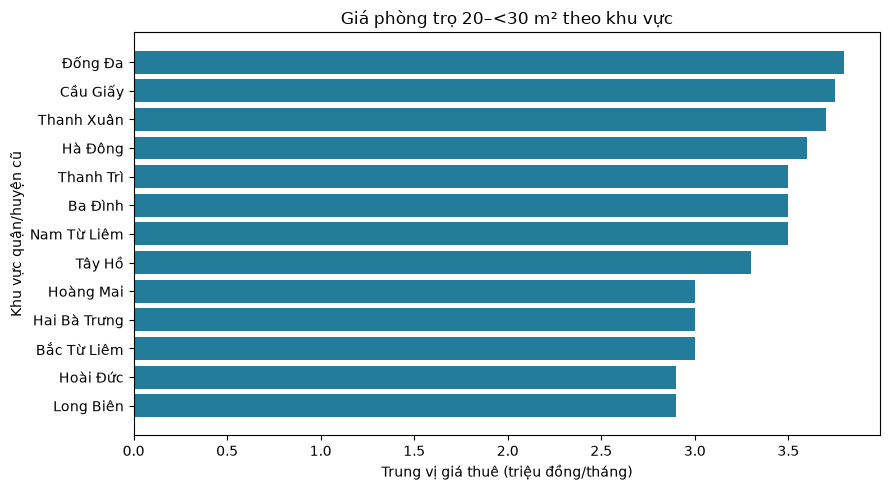

In [28]:
plt.figure(figsize=(9, 5))
plt.barh(gia_cung_dt.index, gia_cung_dt["median"], color="#247C9B")
plt.title("Giá phòng trọ 20–<30 m² theo khu vực")
plt.xlabel("Trung vị giá thuê (triệu đồng/tháng)")
plt.ylabel("Khu vực quận/huyện cũ")
plt.tight_layout()
plt.show()

**Nhận xét**

Giữ riêng các phòng trọ từ 20 đến dưới 30 m², Long Biên và Hoài Đức đều có trung vị 2,9 triệu đồng/tháng, với số mẫu lần lượt 12 và 30 tin. Đống Đa đạt 3,8 triệu trên 82 tin; Cầu Giấy 3,75 triệu trên 123 tin. Chênh lệch giữa nhóm thấp và Đống Đa là khoảng 0,9 triệu đồng/tháng. Các khu vực chỉ được đưa vào hình khi có ít nhất 10 tin trong chính nhóm diện tích này.

Khác biệt giá vẫn xuất hiện khi thu hẹp diện tích, nên sự chênh lệch tổng giá giữa khu vực không chỉ là hệ quả của việc gộp phòng nhỏ và lớn. Tuy vậy, khoảng 20–<30 m² chưa đồng nghĩa diện tích hoàn toàn bằng nhau, và chất lượng, vị trí ngõ/phố cùng dịch vụ kèm theo chưa được đo. Kết quả có giá trị như một phép so sánh điều kiện gần nhau hơn, chưa đủ để ước lượng tác động riêng của địa điểm. Nhóm Long Biên ít mẫu hơn đáng kể nên trung vị cần được hiểu thận trọng.

### Biểu đồ 9. Diện tích và giá theo loại chỗ ở

Các tin đủ giá và diện tích được khảo sát trên hai trục số. Khung hiển thị giới hạn theo phân vị 99% của mỗi biến để thể hiện vùng tập trung; dữ liệu dùng cho thống kê vẫn được giữ đầy đủ.

In [29]:
du_du_lieu = data.loc[data[dientich].gt(0) & data[gia_trieu].gt(0)].copy()
khung = du_du_lieu.loc[
    du_du_lieu[dientich].le(du_du_lieu[dientich].quantile(.99)) &
    du_du_lieu[gia_trieu].le(du_du_lieu[gia_trieu].quantile(.99))]
du_du_lieu.groupby(loai)[[dientich, gia_trieu]].median().round(2)

,Diện tích (m²),Giá (triệu đồng/tháng)
Loại chỗ ở,,
biệt thự,171.0,50.0
căn hộ,30.0,4.6
nhà nguyên căn,96.0,29.0
phòng trọ,25.0,3.5


Biểu đồ phân tán mô tả vị trí của từng tin theo diện tích và giá thuê, phân biệt các loại chỗ ở bằng màu.

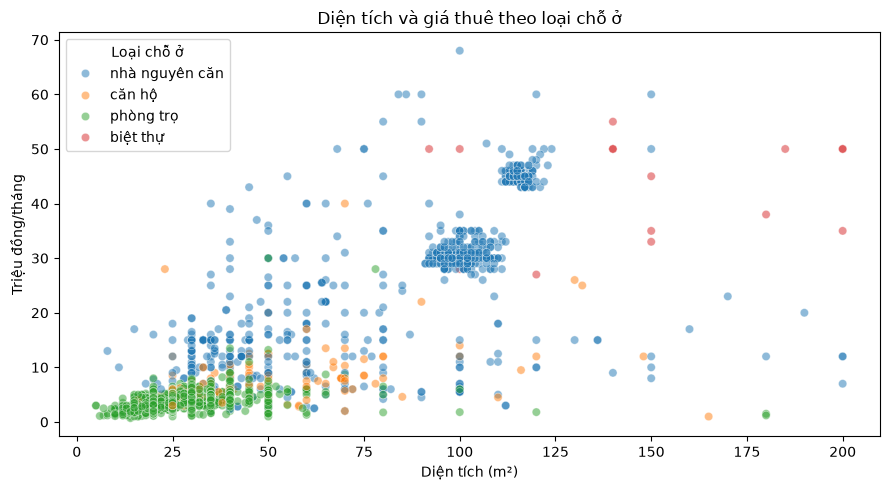

In [30]:
plt.figure(figsize=(9, 5))
sns.scatterplot(data=khung, x=dientich, y=gia_trieu, hue=loai, alpha=.5)
plt.title("Diện tích và giá thuê theo loại chỗ ở")
plt.xlabel("Diện tích (m²)")
plt.ylabel("Triệu đồng/tháng")
plt.tight_layout()
plt.show()

**Nhận xét**

Phòng trọ có diện tích trung vị 25 m² và giá trung vị 3,5 triệu đồng/tháng, trong khi nhà nguyên căn tương ứng là 96 m² và 29 triệu. Căn hộ có diện tích trung vị 30 m², giá 4,6 triệu; biệt thự có diện tích trung vị 171 m² và giá 50 triệu trên 24 tin. Các nhóm tạo thành vùng tập trung khác nhau trên hai trục số, đồng thời tồn tại độ phân tán giá tại những mức diện tích gần nhau. Hình hiển thị khung phân vị 99% của hai biến; thống kê trung vị vẫn dựa trên toàn bộ mẫu đủ giá và diện tích.

Diện tích là thuộc tính hữu ích để phân loại yêu cầu thuê, nhưng chưa đủ để suy ra một mức giá duy nhất. Loại chỗ ở, vị trí và điều kiện sử dụng cùng thay đổi khi diện tích tăng, nên không quy toàn bộ mức giá cao của nhà nguyên căn cho riêng diện tích. Scatter giúp nhận diện các cụm và tin cần xem kỹ, bổ sung cho phép so sánh cùng loại và cùng nhóm diện tích. Các điểm xa vùng tập trung là quan sát cần đối chiếu nguồn, không mặc định là lỗi dữ liệu.

### Biểu đồ 10. Giá phòng trọ theo nhóm diện tích

Giá phòng trọ được tổng hợp theo các khoảng diện tích không chồng lấn. Cận trái thuộc khoảng, cận phải không thuộc khoảng; nhóm cuối không giới hạn trên. Phạm vi biểu diễn gồm các nhóm có ít nhất 20 tin.

In [31]:
phong = du_du_lieu.loc[du_du_lieu[loai].eq("phòng trọ")].copy()
nhom_dt = ["5–<15", "15–<20", "20–<25", "25–<30", "30–<40", "40–<60", "Từ 60"]
phong["Nhóm diện tích (m²)"] = pd.cut(phong[dientich],
    [5, 15, 20, 25, 30, 40, 60, np.inf], right=False, labels=nhom_dt)
thong_ke = phong.groupby("Nhóm diện tích (m²)", observed=True)[gia_trieu].agg(["size", "median"])
thong_ke = thong_ke.loc[thong_ke["size"].ge(20)]
thong_ke.round(2)

,size,median
Nhóm diện tích (m²),,
5–<15,63,2.00
15–<20,253,2.50
20–<25,416,3.08
25–<30,531,3.60
30–<40,394,4.00
40–<60,123,5.00
Từ 60,22,5.00


Biểu đồ cột thể hiện giá phòng trọ trung vị của các nhóm diện tích đủ mẫu.

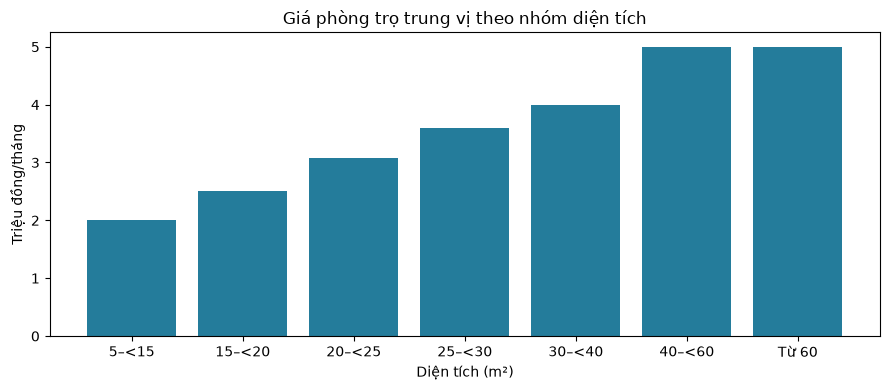

In [32]:
plt.figure(figsize=(9, 4))
plt.bar(thong_ke.index.astype(str), thong_ke["median"], color="#247C9B")
plt.title("Giá phòng trọ trung vị theo nhóm diện tích")
plt.xlabel("Diện tích (m²)")
plt.ylabel("Triệu đồng/tháng")
plt.tight_layout()
plt.show()

**Nhận xét**

Phòng trọ diện tích 5–<15 m² có giá trung vị 2 triệu đồng/tháng trên 63 tin; nhóm từ 60 m² có trung vị 5 triệu trên 22 tin. Chênh lệch giữa hai nhóm là 3 triệu đồng/tháng. Các khoảng diện tích ở giữa cho phép nhận diện mức giá thường gặp của từng quy mô phòng, thay vì suy giá theo một đường thẳng từ scatter. Chỉ các nhóm có ít nhất 20 tin được thể hiện trên biểu đồ.

Kết quả hỗ trợ cân đối giữa ngân sách và nhu cầu không gian: tìm phòng nhỏ hơn có thể mở thêm lựa chọn ở dải giá thấp, nhưng không bảo đảm giá giảm đúng một tỷ lệ cố định. Tập tin trong mỗi nhóm có thể nằm ở các khu vực và phân khúc khác nhau; vì vậy trung vị nhóm chưa phải đơn giá cho mỗi phần diện tích tăng thêm. Khi tư vấn một yêu cầu cụ thể, cần kết hợp nhóm diện tích với khu vực, giá/m² và các tin phù hợp thực tế. Nhóm từ 60 m² có số mẫu ít hơn các nhóm phổ biến nên không đại diện đầy đủ cho phòng trọ lớn.

## 7. Kết luận và giới hạn

- Tập phân tích gồm **2.861 tin thuộc 23 khu vực**, trong đó **2.834 tin** đủ giá và diện tích. Các nhận xét áp dụng cho mẫu tin đăng của hai nguồn đã thu thập.
- Giá phòng trọ trung vị giữa các khu vực đủ mẫu nằm từ **2,9 đến 4,0 triệu đồng/tháng**; chênh lệch khu vực còn xuất hiện khi giữ nhóm diện tích 20–<30 m².
- Hoài Đức có **67,9%** tin phòng trọ đáp ứng ngưỡng 3 triệu. Trong dải 3–<5 triệu, Nam Từ Liêm có **169 tin**, nhiều nhất trong các khu vực trên hình.
- Giá/m² bổ sung thông tin cho tổng giá thuê; Long Biên có trung vị khoảng **107,8 nghìn đồng/m²/tháng**, Thanh Xuân khoảng **156,25 nghìn**.

Tin đăng chưa chứng minh giao dịch thuê thành công hay tình trạng còn trống. Các nguồn có cơ cấu loại chỗ ở khác nhau, có thể cùng đăng một chỗ ở, và chưa đo được đầy đủ tiện ích hoặc vị trí chi tiết. Không suy nguyên nhân từ các khác biệt nhóm; không phân tích xu hướng tháng vì ngày gốc chưa đủ tin cậy. Phường/xã mới còn thiếu nên giá theo khu vực được trình bày bằng nhãn quận/huyện cũ.